# COMP3991 Lab 1 — Limits and the incremental form of the derivative

**Week 1 · 2 hours · follows Lecture 1**

Notation and laws come from Cohen, *Calculus Unraveled*. The lecture used the same symbols; this lab does too.

| Item | Detail |
|---|---|
| Syllabus | 1.0–1.4 Limits; 2.1 Continuity; 2.2 Difference quotient |
| Cohen | Ch. 4 (pp. 117–150); §§5.1–5.2 (pp. 152–159); continuity definition §3.8 |
| Companion notebooks | [ch04_limits_exercises.ipynb](https://github.com/mikexcohen/Calculus_book/blob/main/exercises/ch04_limits_exercises.ipynb) · [ch04_limits_figures.ipynb](https://github.com/mikexcohen/Calculus_book/blob/main/figures/ch04_limits_figures.ipynb) · [ch05_fundamentalsDerivatives_exercises.ipynb](https://github.com/mikexcohen/Calculus_book/blob/main/exercises/ch05_fundamentalsDerivatives_exercises.ipynb) · [ch05_fundamentalsDerivatives_figures.ipynb](https://github.com/mikexcohen/Calculus_book/blob/main/figures/ch05_fundamentalsDerivatives_figures.ipynb) |
| YouTube | [Calculus Unraveled exercise playlist, Ch. 4–5](https://www.youtube.com/playlist?list=PLn0OLiymPak2TFbFj2SD6-p-3-jOah7fe) |

Run this notebook in **Google Colab** (recommended by Cohen) or locally with `numpy`, `sympy`, and `matplotlib`.

**How this notebook is organised.** Each task has **questions** (and a student work cell), then a separate **Solutions (tutor)** cell. Tutors: delete or hide every **Solutions (tutor)** cell before distributing.

**Suggested timing**

| Minutes | Task |
|---|---|
| 0–15 | Setup and Task 0 (notation) |
| 15–40 | Task 1 Numerical limits |
| 40–60 | Task 2 Four properties in SymPy |
| 60–85 | Task 3 $\sin(\varphi)/\varphi$ |
| 85–100 | Task 4 Continuity |
| 100–110 | Task 5 Incremental form |
| 110–120 | Task 6 One weight, one data point |


## Notation used in this lab

Every abbreviation below is defined here and then used without re-explaining it.

| Symbol / phrase | Cohen | Meaning |
|---|---|---|
| $\displaystyle\lim_{x\to a}f(x)=L$ | (4.1) | **two-sided limit**: $L$ is the limit at $a$ |
| $\displaystyle\lim_{x\to a^{-}}f(x)=L^{-}$ | (4.2) | **one-sided limit from the left** ($x<a$) |
| $\displaystyle\lim_{x\to a^{+}}f(x)=L^{+}$ | (4.3) | **one-sided limit from the right** ($x>a$) |
| **d.n.e.** | §4.5 | **d**oes **n**ot **e**xist (the two-sided limit) |
| plug-in method | §4.4 | substitute $x=a$ when $f$ is continuous at $a$ |
| $\gamma$ | §4.6 | a constant (scalar) |
| $H(x)$ | (4.13) | **Heaviside** step: $0$ for $x<0$, $1$ for $x\ge 0$ |
| $m=\Delta y/\Delta x$ | (5.1) | slope of a line ($\Delta$: a “big” interval) |
| $h$ | §5.2 | shorthand for $\Delta x$ (a vanishing step) |
| $\mathrm{d}y/\mathrm{d}x$ | (5.4) | **Leibniz** notation for the derivative |
| $f'$ | §5.3 | **Lagrange** notation for the same derivative |
| difference quotient | syllabus 2.2 | the ratio $\bigl[f(x+h)-f(x)\bigr]/h$ *before* taking $h\to 0$ |
| $\hat{y}=wx$ | Task 6 | prediction: weight $w$ times data $x$ |
| $C(w)=(wx-y)^{2}$ | Task 6 | squared-error cost (prediction versus actual $y$) |

**Convention (§4.5).** “The limit exists” or “the limit is $L$” means the **two-sided** limit: $L^{-}=L^{+}=L$. If the one-sided limits exist but differ, write **d.n.e.**

The syllabus writes $\lim_{x\to 0}(\sin x)/x$. Cohen proves the same statement with the angle $\varphi$, in **radians**: $\lim_{\varphi\to 0}\sin(\varphi)/\varphi=1$ (4.24). In code we use the variable `phi` (or `x`) for that angle.


## Task 0 — Setup (questions)

Run the next cell. If you are on Colab and a package is missing, uncomment the `pip` line.

**0a.** What three Python libraries does this lab use, and what is each for (numbers, algebra, plots)?


In [ ]:
# %pip install numpy sympy matplotlib

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

np.set_printoptions(precision=8, suppress=True)
sp.init_printing()

print("numpy", np.__version__, "| sympy", sp.__version__)


numpy 2.1.3 | sympy 1.14.0


**Your answer (Task 0)**

- 0a:


## Task 1 — Numerical limits (questions)

Cohen §§4.1–4.5: a limit is the value $f$ *approaches*, not necessarily $f(a)$.

The helper `approach_table` evaluates $f$ at points getting closer to `a` from the left ($x\to a^{-}$) and from the right ($x\to a^{+}$).

Run the helper, then the three examples. For each, answer: do $L^{-}$ and $L^{+}$ agree? Does the two-sided limit exist, and what is it? Write **d.n.e.** if the two-sided limit does not exist.

**1a.** $\displaystyle\lim_{x\to 3}(x^{2}-2x)$

**1b.** $\displaystyle\lim_{x\to 2}\dfrac{x^{2}+3x-10}{x-2}$  
(Cohen’s factoring example (4.4). Plug-in gives $0/0$.)

**1c.** $\displaystyle\lim_{x\to 2}\dfrac{\lvert x-2\rvert}{x-2}$  
(Cohen (4.9)--(4.12).)


In [ ]:
def approach_table(f, a, steps=None):
    '''Return x-values and f(x) approaching a from left and right.'''
    if steps is None:
        steps = np.array([1e-1, 1e-2, 1e-3, 1e-4, 1e-5])
    x_left = a - steps   # x -> a from the left  (x < a)
    x_right = a + steps  # x -> a from the right (x > a)
    return x_left, f(x_left), x_right, f(x_right)


def show_table(name, f, a):
    xl, fl, xr, fr = approach_table(f, a)
    print(f"\n{name}, a = {a}")
    print(f"{'x left':>12} {'f left ~ L-':>16} {'x right':>12} {'f right ~ L+':>16}")
    for i in range(len(xl)):
        print(f"{xl[i]:12.7g} {fl[i]:16.8g} {xr[i]:12.7g} {fr[i]:16.8g}")


show_table("1a  x**2 - 2*x", lambda x: x**2 - 2*x, 3)
show_table("1b  (x**2 + 3*x - 10)/(x - 2)", lambda x: (x**2 + 3*x - 10) / (x - 2), 2)
show_table("1c  abs(x-2)/(x-2)", lambda x: np.abs(x - 2) / (x - 2), 2)



1a  x**2 - 2*x, a = 3
      x left      f left ~ L-      x right     f right ~ L+
         2.9             2.61          3.1             3.41
        2.99           2.9601         3.01           3.0401
       2.999         2.996001        3.001         3.004001
      2.9999           2.9996       3.0001           3.0004
     2.99999          2.99996      3.00001          3.00004

1b  (x**2 + 3*x - 10)/(x - 2), a = 2
      x left      f left ~ L-      x right     f right ~ L+
         1.9              6.9          2.1              7.1
        1.99             6.99         2.01             7.01
       1.999            6.999        2.001            7.001
      1.9999           6.9999       2.0001           7.0001
     1.99999          6.99999      2.00001          7.00001

1c  abs(x-2)/(x-2), a = 2
      x left      f left ~ L-      x right     f right ~ L+
         1.9               -1          2.1                1
        1.99               -1         2.01                1
       1.999

**Your answers (Task 1)**

- 1a: 3
- 1b: 7
- 1c: d.n.e.


## Task 2 — Four properties of limits in SymPy (questions)

Syllabus 1.2 / Cohen §4.6. There are **four** named properties ($\gamma$ constant; $f,g$ functions of $x$; $x\to a$ often omitted):

| Name | Law | Eq. |
|---|---|---|
| Factorable | $\lim(\gamma f)=\gamma\lim(f)$ | (4.14) |
| Additive | $\lim(f+g)=\lim(f)+\lim(g)$ | (4.15) |
| Multiplicative | $\lim(f\times g)=\lim(f)\times\lim(g)$ | (4.16) |
| Divisive | $\lim(f/g)=\lim(f)/\lim(g)$ | (4.17) |

The divisive property needs $\lim(g)\neq 0$. Subtraction is additive with a negative: $\lim(f-g)=\lim(f)+\lim(-g)$.

In SymPy, `dir='-'` is $x\to a^{-}$ and `dir='+'` is $x\to a^{+}$.

**2a.** Using only the four properties (and $\lim_{x\to a}x=a$), compute **by hand**

$$\displaystyle\lim_{x\to -1}(2x^{3} + x - 4).$$

Name which properties you used, then confirm with `sp.limit`.

**2b.** Why does `sp.limit((x**2 + 3*x - 10)/(x - 2), x, 2)` succeed even though the expression is undefined at $x=2$?

**2c.** At $a=2$, for $u(x)=x^{2}$, $v(x)=x+1$, $\gamma=3$, check that each of the four properties holds in SymPy (left-hand side versus right-hand side).

**2d.** Compare `sp.limit` of $\lvert x-2\rvert/(x-2)$ as $x\to 2$ from the left, from the right, and two-sided. Does the two-sided result match Cohen?


In [ ]:
x = sp.symbols("x")

# 2a — replace None with your hand calculation
hand_value = -7
sympy_value = sp.limit(2*x**3 + x - 4, x, -1)
print("hand:", hand_value, "| sympy:", sympy_value)

# 2b — write your reason in the markdown answer cell

# 2c — four properties at a = 2
u = x**2
v = x + 1
gamma = 3
a = 2
print("factorable     ", sp.limit(gamma * u, x, a), "vs", gamma * sp.limit(u, x, a))
print("additive       ", sp.limit(u + v, x, a), "vs", sp.limit(u, x, a) + sp.limit(v, x, a))
print("multiplicative ", sp.limit(u * v, x, a), "vs", sp.limit(u, x, a) * sp.limit(v, x, a))
print("divisive       ", sp.limit(u / v, x, a), "vs", sp.limit(u, x, a) / sp.limit(v, x, a))

# 2d
jump = sp.Abs(x - 2) / (x - 2)
Lm = sp.limit(jump, x, 2, dir="-")
Lp = sp.limit(jump, x, 2, dir="+")

print("L-       ", Lm)
print("L+        ", Lp)
print("two-sided ", Lp if Lm == Lp else "d.n.e.")


hand: -7 | sympy: -7
factorable      12 vs 12
additive        7 vs 7
multiplicative  12 vs 12
divisive        4/3 vs 4/3
L-        -1
L+         1
two-sided  d.n.e.


**Your answers (Task 2)**

- 2a: Additive & Factorable
- 2b: SymPy cancels the common factor (x - 2), so it can evaluate the     simplified expression x + 5 at x = 2, giving 7. The original expression is undefined at x = 2, but the limit exists because the discontinuity is removable.
- 2c: All four properties hold at a = 2
- 2d: Left limit = -1, right limit = +1, two-sided limit = d.n.e. This matches Cohen.


## Task 3 — $\displaystyle\lim_{\varphi\to 0}\sin(\varphi)/\varphi$ (questions)

Syllabus 1.3 / Cohen (4.24). Use **radians**. Plug-in gives $0/0$. On the unit circle, $\sin(\varphi)$ is a chord and $\varphi$ is the arc; they become equal as $\varphi\to 0$. The squeeze theorem (§4.9; also called sandwich / pinch) is the formal tool.

In NumPy, `np.sin` expects radians. The hole at $\varphi=0$ appears as `nan` (not a number) when you divide by zero.

Run the table and the plot, then answer.

**3a.** What value is the table approaching? What kind of discontinuity is the hole at $\varphi=0$?

**3b.** What happens if you use degrees by mistake? Compare $\sin(\varphi)/\varphi$ in radians with `np.sin(np.deg2rad(h))/h` (sine of $h$ degrees, divided by $h$). Why do Cohen and the syllabus insist on radians?

**3c.** Cohen’s cosine companion (4.25)--(4.30): estimate $\displaystyle\lim_{\varphi\to 0}\dfrac{\cos(\varphi)-1}{\varphi}$ numerically, guess the exact value, then check with `sp.limit`.

**3d (stretch).** Estimate $\displaystyle\lim_{\varphi\to 0}\dfrac{1-\cos(\varphi)}{\varphi^{2}}$.


varphi        sin(varphi)/varphi
           1  0.8414709848
         0.5  0.9588510772
         0.2  0.9933466540
         0.1  0.9983341665
        0.01  0.9999833334
       0.001  0.9999998333
      0.0001  0.9999999983

sympy: 1


/tmp/ipykernel_2360/2308995672.py:10: RuntimeWarning: invalid value encountered in divide
  y = np.sin(t) / t  # radians; t = 0 is nan — the hole


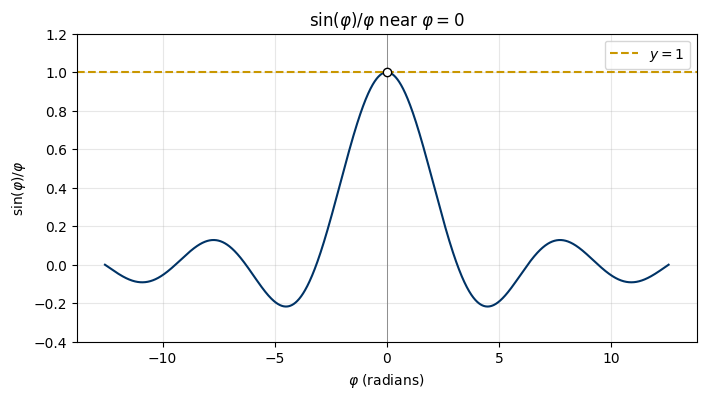

sin(h)/h with h in radians: 0.9999998333333416
sin(h degrees)/h:           0.017453292519057202

varphi     (cos(varphi)-1)/varphi
           1  -0.4596976941
         0.5  -0.2448348762
         0.2  -0.0996671108
         0.1  -0.0499583472
        0.01  -0.0049999583
       0.001  -0.0005000000
      0.0001  -0.0000500000
sympy (cos-1)/varphi: 0
sympy (1-cos)/varphi**2: 1/2


In [ ]:
phi = sp.symbols("varphi")
phis = np.array([1.0, 0.5, 0.2, 0.1, 0.01, 0.001, 1e-4])
print("varphi        sin(varphi)/varphi")
for h in phis:
    print(f"{h:12.4g}  {np.sin(h)/h:.10f}")

print("\nsympy:", sp.limit(sp.sin(phi) / phi, phi, 0))

t = np.linspace(-4 * np.pi, 4 * np.pi, 2001)
y = np.sin(t) / t  # radians; t = 0 is nan — the hole

plt.figure(figsize=(8, 4))
plt.plot(t, y, color="#003366")
plt.scatter([0], [1], facecolors="white", edgecolors="black", zorder=5)
plt.axhline(1.0, color="#C99700", linestyle="--", label=r"$y = 1$")
plt.axvline(0.0, color="gray", linewidth=0.6)
plt.ylim(-0.4, 1.2)
plt.xlabel(r"$\varphi$ (radians)")
plt.ylabel(r"$\sin(\varphi)/\varphi$")
plt.title(r"$\sin(\varphi)/\varphi$ near $\varphi=0$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3b
h = 0.001
print("sin(h)/h with h in radians:", np.sin(h) / h)
print("sin(h degrees)/h:          ", np.sin(np.deg2rad(h)) / h)

# 3c — fill in a guess, then check
print("\nvarphi     (cos(varphi)-1)/varphi")
for val in phis:
    print(f"{val:12.4g}  {(np.cos(val) - 1) / val:.10f}")
print("sympy (cos-1)/varphi:", sp.limit((sp.cos(phi) - 1) / phi, phi, 0))

# 3d (stretch) — uncomment when you try it
print("sympy (1-cos)/varphi**2:", sp.limit((1 - sp.cos(phi)) / phi**2, phi, 0))


**Your answers (Task 3)**

- 3a: The table approaches 1. The hole is a removable discontinuity.
- 3b: In degrees, the limit is π / 180 ≈ 0.01745, not 1. Radians are required for the limit to be 1
- 3c: The limit is 0. Table approaches 0; SymPy confirms 0.
- 3d: 1 / 2


## Task 4 — Continuity at a point (questions)

Syllabus 2.1 / Cohen §3.8.1. $f$ is **continuous at** $x=a$ when all three hold:

1. $f(a)$ is defined;
2. $\lim_{x\to a}f(x)$ exists (two-sided);
3. $\lim_{x\to a}f(x)=f(a)$.

Cohen’s four types of discontinuity (§3.8.2): **jump**, **infinite**, **removable**, **oscillating**.

The Heaviside step (4.13) is $H(x)=0$ for $x<0$ and $H(x)=1$ for $x\ge 0$.

Run `classify` for A–F. Fill the table. Write **d.n.e.** when the two-sided limit does not exist. If SymPy’s two-sided output disagrees with $L^{-}$ and $L^{+}$, follow Cohen (see Task 2d).


In [ ]:
def classify(name, expr, a):
    fa = expr.subs(x, a)
    Lm = sp.limit(expr, x, a, dir="-")
    Lp = sp.limit(expr, x, a, dir="+")
    L = Lp if Lm == Lp else "d.n.e."
    print(name)
    print("  f(a)         ", fa)
    print("  two-sided    ", L)
    print("  L-           ", Lm)
    print("  L+           ", Lp)
    print()

Heaviside = sp.Heaviside(x, 1)  # H(x): 0 for x < 0, 1 for x >= 0

classify("A  x**2 - 2*x                 at 3", x**2 - 2 * x, 3)
classify("B  sin(x)/x                   at 0", sp.sin(x) / x, 0)
classify("C  |x-2|/(x-2)                at 2", sp.Abs(x - 2) / (x - 2), 2)
classify("D  1/x                        at 0", 1 / x, 0)
classify("E  Heaviside H(x)             at 0", Heaviside, 0)
classify("F  (x**2 - 2*x)/(x**2 - 4)    at 2", (x**2 - 2 * x) / (x**2 - 4), 2)


A  x**2 - 2*x                 at 3
  f(a)          3
  two-sided     3
  L-            3
  L+            3

B  sin(x)/x                   at 0
  f(a)          nan
  two-sided     1
  L-            1
  L+            1

C  |x-2|/(x-2)                at 2
  f(a)          nan
  two-sided     d.n.e.
  L-            -1
  L+            1

D  1/x                        at 0
  f(a)          zoo
  two-sided     d.n.e.
  L-            -oo
  L+            oo

E  Heaviside H(x)             at 0
  f(a)          1
  two-sided     d.n.e.
  L-            0
  L+            1

F  (x**2 - 2*x)/(x**2 - 4)    at 2
  f(a)          nan
  two-sided     1/2
  L-            1/2
  L+            1/2



**Your answers (Task 4)**

Copy and complete. Types if not continuous: jump / infinite / removable / oscillating / —.

| | $f(a)$ defined? | two-sided limit? | continuous at $a$? | type if not |
|---|---|---|---|---|
| A polynomial at $3$ | Yes|3 |Yes | |
| B $\sin x/x$ at $0$ | No|1 |No |Removable|
| C $\lvert x-2\rvert/(x-2)$ at $2$ |No|d.n.e. |No |Jump |
| D $1/x$ at $0$ | No|d.n.e. |No |Infinite |
| E $H(x)$ at $0$ | Yes|d.n.e |No |Jump |
| F $(x^{2}-2x)/(x^{2}-4)$ at $2$ |No| 1/2 |No |Removable |


## Task 5 — Difference quotient and $\mathrm{d}y/\mathrm{d}x$ (questions)

Syllabus 2.2 / Cohen §5.2. Slope of a line is $m=\Delta y/\Delta x$ (5.1). The derivative is those slopes as the interval becomes tiny:

$$\frac{\mathrm{d}y}{\mathrm{d}x}
= \lim_{h\to 0}\left[\frac{f(x+h)-f(x)}{h}\right]
\qquad\text{(5.4, incremental / limits-based form).}$$

Here $h$ is shorthand for $\Delta x$. The syllabus calls $\bigl[f(x+h)-f(x)\bigr]/h$ the **difference quotient**. Leibniz $\mathrm{d}y/\mathrm{d}x$ and Lagrange $f'$ name the limit, when it exists.

**5a.** Implement `difference_quotient`. Run it for $f(x)=x^{2}$ at $x=3$. What value should the table approach? Why?

**5b.** Derive $\mathrm{d}y/\mathrm{d}x=2x$ on paper from (5.4) (Cohen §5.2.2), then confirm with `sp.diff`. SymPy’s `diff` is the answer after the limit has been solved; it is not a substitute for writing (5.4) by hand once.

**5c.** Repeat the table for $f(x)=\lvert x\rvert$ at $x=0$, using both $h\to 0^{+}$ and $h\to 0^{-}$. Does $f'(0)$ exist? Why or why not? (Cohen §5.6.)


In [ ]:
def f(x):
    return x**2

def difference_quotient(f, x, h):
    # TODO: return (Cohen (5.4), the ratio inside the limit)
    return (f(x + h) - f(x)) / h

x0 = 3.0
hs = np.array([1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6])

print(f"{'h = Delta x':>14} {'quotient':>16}")
for h in hs:
    q = difference_quotient(f, x0, h)
    print(f"{h:14.4g} {q:16.10f}")

print("sympy derivative of x**2:", sp.diff(x**2, x))

# 5c — |x| at 0
print("\n|x| at 0, h -> 0+")
for h in hs:
    print(h, (np.abs(0 + h) - np.abs(0)) / h)
print("|x| at 0, h -> 0-")
for h in hs:
    print(-h, (np.abs(0 - h) - np.abs(0)) / (-h))


   h = Delta x         quotient
           0.1     6.1000000000
          0.01     6.0100000000
         0.001     6.0010000000
        0.0001     6.0001000000
         1e-05     6.0000100000
         1e-06     6.0000010009
sympy derivative of x**2: 2*x

|x| at 0, h -> 0+
0.1 1.0
0.01 1.0
0.001 1.0
0.0001 1.0
1e-05 1.0
1e-06 1.0
|x| at 0, h -> 0-
-0.1 -1.0
-0.01 -1.0
-0.001 -1.0
-0.0001 -1.0
-1e-05 -1.0
-1e-06 -1.0


**Your answers (Task 5)**

- 5a: The table approaches 6. This is because the derivative of x² is 2x, and at x = 3, 2(3) = 6. The difference quotient is the average slope, which approaches the instantaneous slope (the derivative) as h gets smaller.
- 5b: Derivation: (x + h)² - x² = 2xh + h², so the difference quotient simplifies to 2x + h. Taking h → 0 gives 2x. Confirmed with sp.diff.
- 5c: The right limit is 1, the left limit is -1. They disagree, so the two-sided limit does not exist. Therefore f'(0) does not exist. This is because |x| has a sharp corner at x = 0, so there is no single tangent slope there.


## Task 6 — Model: one weight, one data point (questions)

A machine-learning model is a recipe that turns an input into a guess. The simplest recipe with one knob is

$$\hat{y} = wx.$$

- $x$ = the **data** (given; not something we choose)
- $w$ = the **weight** (the only knob we can turn)
- $\hat{y}$ = the **prediction** (what the recipe currently says)
- $y$ = the **actual** value (the target)

The **squared-error cost** measures how wrong the guess is:

$$C(w) = \bigl(\hat{y}-y\bigr)^{2} = (wx-y)^{2}.$$

Miss by $1$, cost is $1$. Miss by $3$, cost is $9$.

You are **not** training a network and you are **not** running gradient descent. You only answer Lecture 1’s question, now aimed at the knob that is actually free:

> The data $x$ and the target $y$ are fixed. If I nudge the weight $w$ by a tiny $h$, how does the cost change?

That is the **difference quotient in $w$**. Its two-sided limit, when it exists, is $\mathrm{d}C/\mathrm{d}w$ (Cohen (5.4), with the variable named $w$ instead of $x$). Here $h$ is shorthand for $\Delta w$.

**Given data (one point).** $x=3$, $y=2$. Start at $w=1$.

Then the current prediction is $\hat{y}=1\cdot 3=3$. Compute $C(1)$ in the code cell.

Complete Task 5’s `difference_quotient` first. Reuse it here: the function of the nudged variable is $C$, and the step is in $w$.


### Task 6 Part A — questions

The prediction at the nudged weight is $\hat{y}_{\mathrm{new}}=(w+h)x$. So

$$\frac{C(w+h)-C(w)}{h}
= \frac{\bigl((w+h)x-y\bigr)^{2}-(wx-y)^{2}}{h}
\qquad (h\neq 0).$$

Plug-in of $h=0$ is $0/0$. Algebra first, same as $\lim_{h\to 0}\bigl[(x+h)^{2}-x^{2}\bigr]/h$ in Cohen §5.2.2.

**A1.** Expand and simplify the difference quotient. Do not set $h=0$ until $h$ has cancelled.

**A2.** Take $\lim_{h\to 0}$. That limit is $C'(w)$, or $\mathrm{d}C/\mathrm{d}w$.

**A3.** Substitute $x=3$, $y=2$, $w=1$. What number do you get?

**A4.** Tabulate the difference quotient at $w=1$ for $h=10^{-1},10^{-2},\ldots,10^{-6}$.


In [ ]:
# Complete Task 5 first so difference_quotient is defined.
x_data, y_actual, w0 = 3.0, 2.0, 1.0

def C(w, x=x_data, y=y_actual):
    '''Squared error: prediction yhat = w*x versus actual y.'''
    yhat = w * x
    return (yhat - y) ** 2

print("C(1) =", C(w0))

# A1–A3 (your algebra):
# simplified difference quotient =
# C'(w) =
# C'(1) =

print(f"\n{'h':>12} {'quotient':>14}")
for h in hs:
    q = difference_quotient(C, w0, h)
    print(f"{h:12.4g} {q:14.8f}")


C(1) = 1.0

           h       quotient
         0.1     6.90000000
        0.01     6.09000000
       0.001     6.00900000
      0.0001     6.00090000
       1e-05     6.00009000
       1e-06     6.00000900


**Your answers (Task 6 Part A)**

- A1: 2x(wx - y) + hx²
- A2: C'(w) = 2x(wx - y)
- A3: C'(1) = 6
- A4: The table approaches 6.


### Task 6 Part B — questions

$C'(1)$ is a number with a sign. That sign is the modelling answer.

**B1.** At $w=1$, do you increase or decrease $w$ to reduce the cost? Why (use the sign of $C'(1)$)?

**B2.** The cost is smallest for this one point when the slope is zero:

$$C'(w)=0 \quad\Rightarrow\quad 2x(wx-y)=0.$$

Solve for $w$ with the given $x$ and $y$. Check $C$ at that weight.

**B3.** What is the sign of $C'(w)$ if $w>2/3$? If $w<2/3$? (Keep $x=3>0$, $y=2$.) In each case, which way do you nudge $w$ to reduce cost?

**B4.** You now have a rule that uses only the difference quotient:

- slope $>0$ → nudge $w$ **down**
- slope $<0$ → nudge $w$ **up**
- slope $=0$ → stop (for this one point you are at the $w$ from B2)

Do **not** implement a training loop. Write four short answers.


**Your answers (Task 6 Part B)**

- B1: Decrease w, because C'(1) = 6 > 0, meaning cost increases as w increases.
- B2: w = 2/3, and C(2/3) = 0.
- B3: If w > 2/3, nudge down; if w < 2/3, nudge up.
- B4: Positive slope → down, negative → up, zero → stop. This is gradient descent.


### Task 6 — what to submit (questions)

Write four sentences:

1. State the model $\hat{y}=wx$, the cost $C(w)=(wx-y)^{2}$, and the given numbers. What is free to change?
2. What is the simplified difference quotient, and what is $C'(1)$?
3. Do you nudge $w$ up or down at $w=1$? What weight makes $C'=0$ on this one point?
4. If $w$ is below that best weight, which way do you nudge? What later algorithm is this the idea of (without running it)?


**Your four sentences**

1. The model is ŷ = wx with cost C(w) = (wx - y)². Given x = 3, y = 2, the only thing free to change is w.
2. The simplified difference quotient is 2x(wx - y) + hx², and the derivative is C'(w) = 2x(wx - y). At w = 1, C'(1) = 6.
3. At w = 1, the slope is positive, so we nudge w down to reduce cost. The weight that makes the cost zero is w = 2/3.
4. If w is below 2/3, the slope is negative, so we nudge w up. This is the idea of gradient descent.


## Submit

**Submit (myeLearning):** this notebook with Tasks 0–6 completed (tables, plots, short written answers). Use **d.n.e.** (does not exist), not an undefined shorthand, when a two-sided limit fails. Task 6 is the modelling closer: one weight, one data point.

**Discussion forum (RISE):** post one sentence on a limit that behaved differently from $f(a)$.

**Tutor:** delete or hide every cell whose heading starts with **Solutions (tutor)** before distributing.

**Next week:** Lecture 2 covers 2.3–2.5 (simple derivatives; product, quotient, chain rule).
